# 02 — EDA : Irradiance solaire
Dataset : *Solar Radiation Prediction* (Kaggle, NASA HI-SEAS, Hawaï, sept.–déc. 2016).
Colonnes : `UNIXTime, Data, Time, Radiation, Temperature, Pressure, Humidity, WindDirection(Degrees), Speed, TimeSunRise, TimeSunSet`.

Objectifs : comprendre les données, les nettoyer, les passer au pas **horaire**, et sauvegarder `data/processed/solar_hourly.csv`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
RAW_PATH = r"C:\Users\USER\Desktop\DM_Projet\Projet-Data-Mining\data\raw\solar_irradiance\SolarPrediction.csv"
OUT_PATH = r"C:\Users\USER\Desktop\DM_Projet\Projet-Data-Mining\data\processed\solar_hourly.csv"

## 1. Chargement et aperçu

In [2]:
df = pd.read_csv(RAW_PATH)
print(df.shape)
df.head()

(32686, 11)


,UNIXTime,Data,Time,Radiation,Temperature,Pressure,Humidity,WindDirection(Degrees),Speed,TimeSunRise,TimeSunSet
0,1475229326,9/29/2016 12:00:00 AM,23:55:26,1.21,48,30.46,59,177.39,5.62,06:13:00,18:13:00
1,1475229023,9/29/2016 12:00:00 AM,23:50:23,1.21,48,30.46,58,176.78,3.37,06:13:00,18:13:00
2,1475228726,9/29/2016 12:00:00 AM,23:45:26,1.23,48,30.46,57,158.75,3.37,06:13:00,18:13:00
3,1475228421,9/29/2016 12:00:00 AM,23:40:21,1.21,48,30.46,60,137.71,3.37,06:13:00,18:13:00
4,1475228124,9/29/2016 12:00:00 AM,23:35:24,1.17,48,30.46,62,104.95,5.62,06:13:00,18:13:00


In [3]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32686 entries, 0 to 32685
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   UNIXTime                32686 non-null  int64  
 1   Data                    32686 non-null  object 
 2   Time                    32686 non-null  object 
 3   Radiation               32686 non-null  float64
 4   Temperature             32686 non-null  int64  
 5   Pressure                32686 non-null  float64
 6   Humidity                32686 non-null  int64  
 7   WindDirection(Degrees)  32686 non-null  float64
 8   Speed                   32686 non-null  float64
 9   TimeSunRise             32686 non-null  object 
 10  TimeSunSet              32686 non-null  object 
dtypes: float64(4), int64(3), object(4)
memory usage: 2.7+ MB


,count,mean,std,min,25%,50%,75%,max
UNIXTime,32686.0,1.478047e+09,3.005037e+06,1.472724e+09,1.475546e+09,1.478026e+09,1.480480e+09,1.483265e+09
Radiation,32686.0,2.071247e+02,3.159164e+02,1.110000e+00,1.230000e+00,2.660000e+00,3.542350e+02,1.601260e+03
Temperature,32686.0,5.110326e+01,6.201157e+00,3.400000e+01,4.600000e+01,5.000000e+01,5.500000e+01,7.100000e+01
Pressure,32686.0,3.042288e+01,5.467316e-02,3.019000e+01,3.040000e+01,3.043000e+01,3.046000e+01,3.056000e+01
Humidity,32686.0,7.501631e+01,2.599022e+01,8.000000e+00,5.600000e+01,8.500000e+01,9.700000e+01,1.030000e+02
WindDirection(Degrees),32686.0,1.434898e+02,8.316750e+01,9.000000e-02,8.222750e+01,1.477000e+02,1.793100e+02,3.599500e+02
Speed,32686.0,6.243869e+00,3.490474e+00,0.000000e+00,3.370000e+00,5.620000e+00,7.870000e+00,4.050000e+01


## 2. Construction de l'index temporel
Le timestamp UNIX est en UTC ; la station est à Hawaï (UTC−10).

In [4]:
df["timestamp"] = pd.to_datetime(df["UNIXTime"], unit="s") - pd.Timedelta(hours=10)
df = df.sort_values("timestamp").set_index("timestamp")
df = df.rename(columns={"WindDirection(Degrees)": "WindDirection"})
df = df[["Radiation", "Temperature", "Pressure", "Humidity", "WindDirection", "Speed"]]
print(df.index.min(), "->", df.index.max())
print("Doublons d'index :", df.index.duplicated().sum())
df = df[~df.index.duplicated(keep="first")]

2016-09-01 00:00:08 -> 2016-12-31 23:55:01
Doublons d'index : 0


## 3. Valeurs manquantes et aberrantes

In [5]:
print(df.isna().sum())
print("Radiation négative :", (df["Radiation"] < 0).sum())
df["Radiation"] = df["Radiation"].clip(lower=0)

Radiation        0
Temperature      0
Pressure         0
Humidity         0
WindDirection    0
Speed            0
dtype: int64
Radiation négative : 0


## 4. Rééchantillonnage horaire (moyenne)

In [6]:
hourly = df.resample("1h").mean()
print("Heures manquantes :", hourly["Radiation"].isna().sum())
hourly = hourly.interpolate(limit=3).dropna()   # on comble les petits trous (<= 3 h)
hourly.shape

Heures manquantes : 151


(2806, 6)

## 5. Visualisations

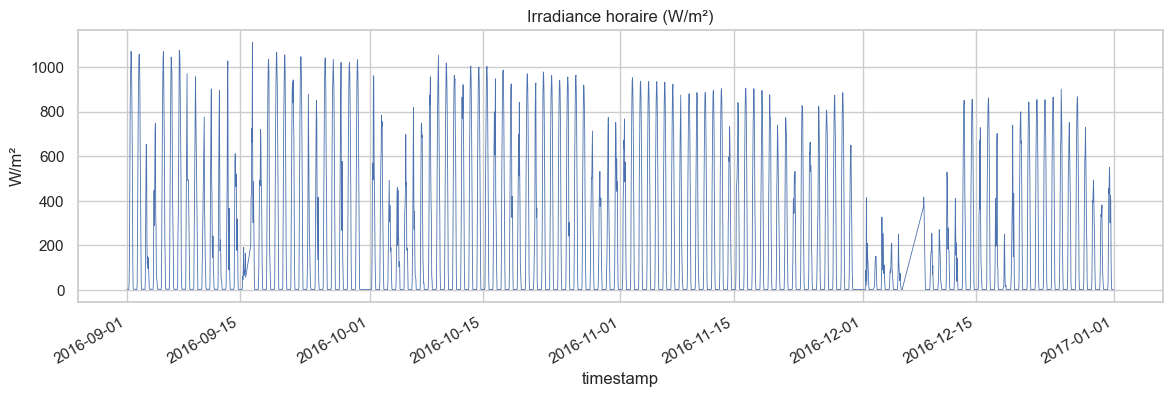

In [7]:
fig, ax = plt.subplots(figsize=(14, 4))
hourly["Radiation"].plot(ax=ax, lw=0.6)
ax.set_title("Irradiance horaire (W/m²)"); ax.set_ylabel("W/m²")
plt.show()

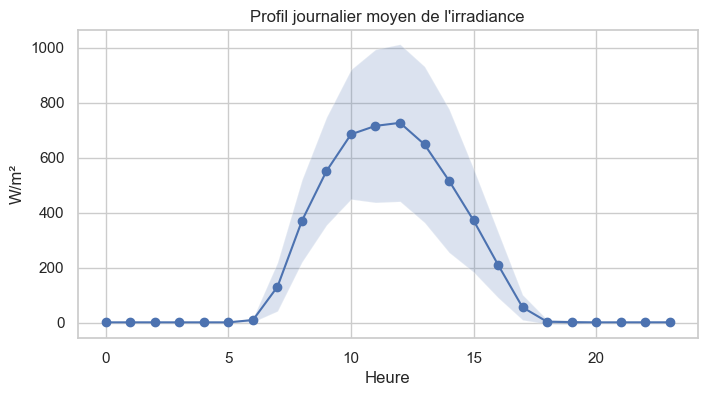

In [8]:
# Profil journalier moyen
hourly["hour"] = hourly.index.hour
profile = hourly.groupby("hour")["Radiation"].agg(["mean", "std"])
plt.figure(figsize=(8, 4))
plt.plot(profile.index, profile["mean"], marker="o")
plt.fill_between(profile.index, profile["mean"] - profile["std"],
                 (profile["mean"] + profile["std"]), alpha=0.2)
plt.title("Profil journalier moyen de l'irradiance"); plt.xlabel("Heure"); plt.ylabel("W/m²")
plt.show()

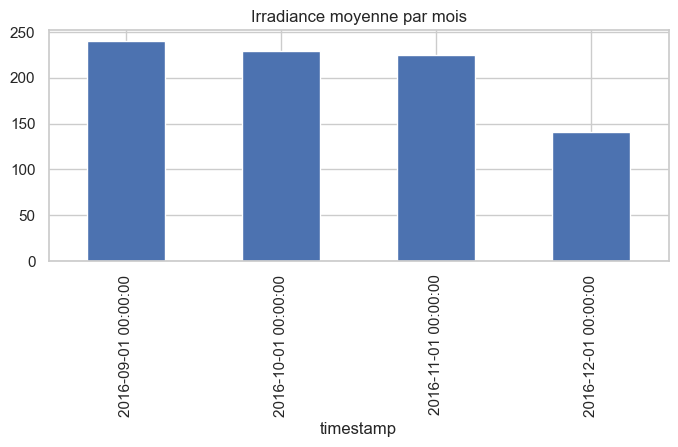

In [9]:
# Évolution mensuelle
monthly = hourly["Radiation"].resample("MS").mean()
monthly.plot(kind="bar", figsize=(8, 3), title="Irradiance moyenne par mois")
plt.show()

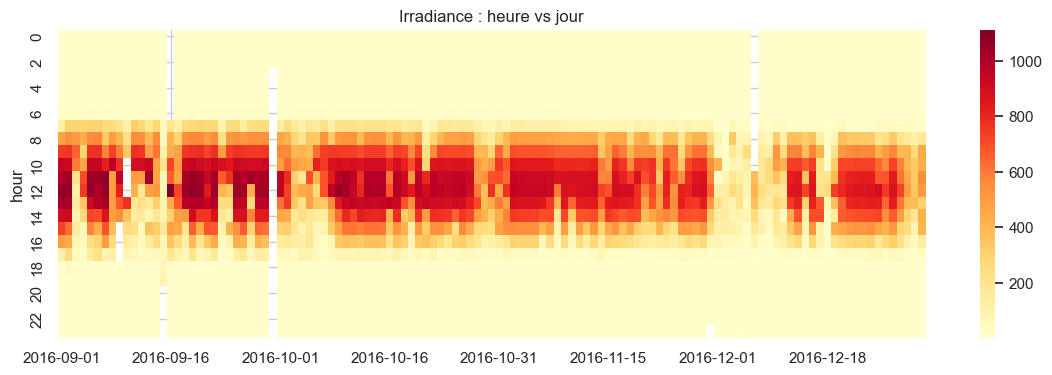

In [10]:
# Carte de chaleur heure x jour
pivot = hourly.pivot_table(index="hour", columns=hourly.index.date, values="Radiation")
plt.figure(figsize=(14, 4))
sns.heatmap(pivot, cmap="YlOrRd", xticklabels=15)
plt.title("Irradiance : heure vs jour"); plt.show()

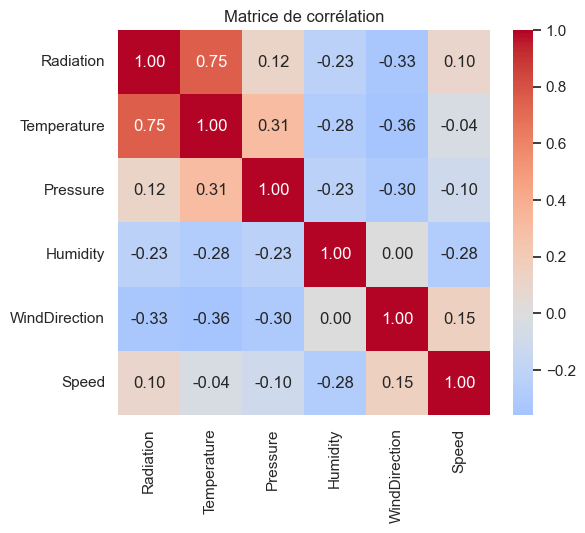

In [11]:
# Corrélations
plt.figure(figsize=(6, 5))
sns.heatmap(hourly.drop(columns="hour").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation"); plt.show()

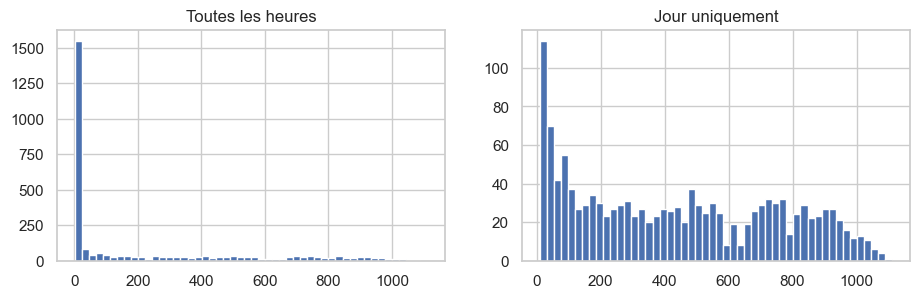

In [12]:
# Distribution (beaucoup de zéros la nuit)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
hourly["Radiation"].hist(bins=50, ax=axes[0]); axes[0].set_title("Toutes les heures")
hourly.loc[hourly["Radiation"] > 10, "Radiation"].hist(bins=50, ax=axes[1]); axes[1].set_title("Jour uniquement")
plt.show()

## 6. Sauvegarde des données traitées

In [13]:
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
hourly.drop(columns="hour").to_csv(OUT_PATH)
print("Sauvegardé :", OUT_PATH, hourly.shape)

Sauvegardé : C:\Users\USER\Desktop\DM_Projet\Projet-Data-Mining\data\processed\solar_hourly.csv (2806, 7)


## Conclusions
- L'irradiance suit un cycle journalier net (nulle la nuit, maximum vers midi) → utiliser des features cycliques (heure, jour de l'année).
- Fort effet de la température ; l'humidité est corrélée négativement.
- Beaucoup de zéros : la persistance est une baseline forte, le LSTM doit la battre.
- Période courte (~4 mois) : attention à la généralisation saisonnière.